In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from collections import deque

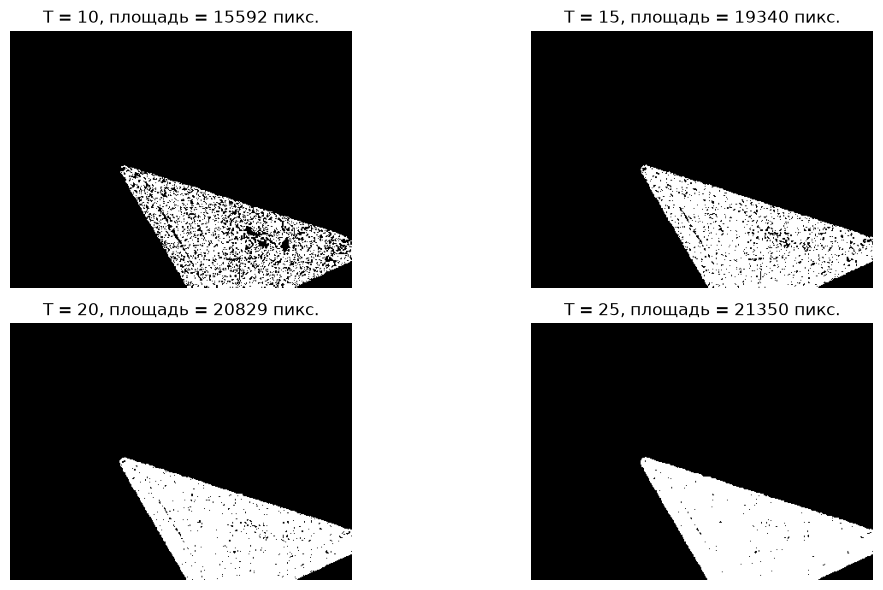

In [7]:
# подбор параметров
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
image_smooth = cv2.medianBlur(image_gray, 5)

def homo_average(pixel, total, count, histogram, T):
    average = total / count
    return abs(pixel - average) <= T

def homo_median(pixel, total, count, histogram, T):
    cumulative = np.cumsum(histogram)
    low = np.searchsorted(cumulative, (count + 1) // 2)
    high = np.searchsorted(cumulative, (count + 2) // 2)
    median_value = (low + high) / 2
    return abs(pixel - median_value) <= T

def region_growing(img, seed_point, criterion, T):
    height, width = img.shape
    y0, x0 = seed_point

    if not (0 <= y0 < height and 0 <= x0 < width):
        raise ValueError('Начальная точка вне изображения')

    mask = np.zeros((height, width), dtype=np.uint8)
    mask[y0, x0] = 255
    queue = deque([(y0, x0)])
    first = int(img[y0, x0])
    histogram = np.zeros(256, dtype=np.int32)
    histogram[first] = 1
    total = first
    count = 1
    neighbours = [
        (-1, 0), (1, 0),
        (0, -1), (0, 1),
        (-1, -1), (-1, 1),
        (1, -1), (1, 1)
    ]

    while queue:
        y, x = queue.popleft()
        for dy, dx in neighbours:
            ny = y + dy
            nx = x + dx

            if (
                0 <= ny < height
                and 0 <= nx < width
                and mask[ny, nx] == 0
            ):
                value = int(img[ny, nx])

                if criterion(value, total, count, histogram, T):
                    mask[ny, nx] = 255
                    queue.append((ny, nx))
                    histogram[value] += 1
                    total += value
                    count += 1

    return mask

    seed_point = (250, 250)
thresholds = [10, 15, 20, 25]
masks_t = [
    region_growing(image_gray, seed_point, homo_average, T)
    for T in thresholds
]
plt.figure(figsize=(12, 6))
for i, (T, current_mask) in enumerate( zip(thresholds, masks_t)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(current_mask, cmap='gray', vmin=0, vmax=255)
    area = np.count_nonzero(current_mask)
    plt.title(f'T = {T}, площадь = {area} пикс.')
    plt.axis('off')

plt.tight_layout()
plt.show()

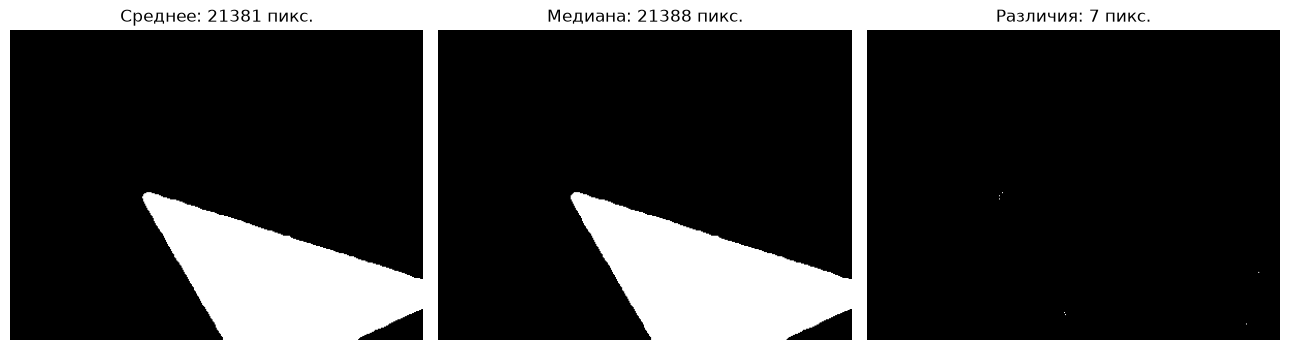

In [8]:
T = 20
mask_average = region_growing(image_smooth, seed_point, homo_average, T)
mask_median = region_growing(image_smooth, seed_point, homo_median, T)

mask_difference = cv2.absdiff(mask_average, mask_median)

plt.figure(figsize=(13, 4))

plt.subplot(1, 3, 1)
plt.imshow(mask_average, cmap='gray', vmin=0, vmax=255)
plt.title(f'Среднее: {np.count_nonzero(mask_average)} пикс.')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_median, cmap='gray', vmin=0, vmax=255)
plt.title(f'Медиана: {np.count_nonzero(mask_median)} пикс.')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(mask_difference, cmap='gray', vmin=0, vmax=255)
plt.title(f'Различия: {np.count_nonzero(mask_difference)} пикс.')
plt.axis('off')

plt.tight_layout()
plt.show()

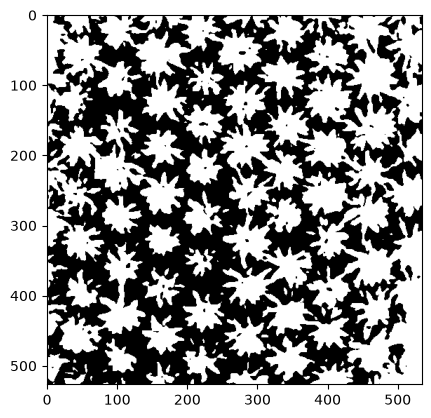

In [9]:
# watershed+distance transform

image = cv2.imread('palm_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

blur = cv2.GaussianBlur(image_gray, (9,9), 0)
ret, thresh = cv2.threshold(blur,0,255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)
plt.imshow(thresh, cmap="gray")

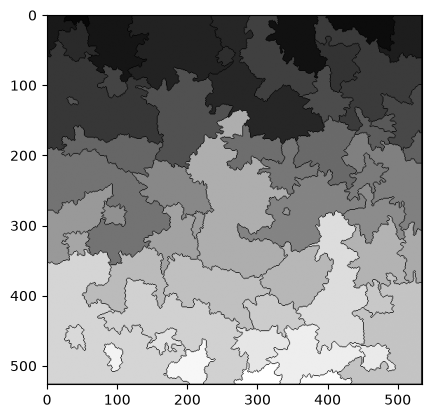

In [10]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5) 
plt.imshow(dist, cmap="gray")

ret, sure_fg = cv2.threshold(dist, 0.4 * dist.max(), 255, cv2.THRESH_BINARY) 
plt.imshow(sure_fg, cmap="gray")

sure_fg = sure_fg.astype(np.uint8)
ret, markers = cv2.connectedComponents(sure_fg) 
plt.imshow(markers, cmap="gray")

markers = cv2.watershed(image, markers)
plt.imshow(markers, cmap="gray")

Найдено пальм: 59


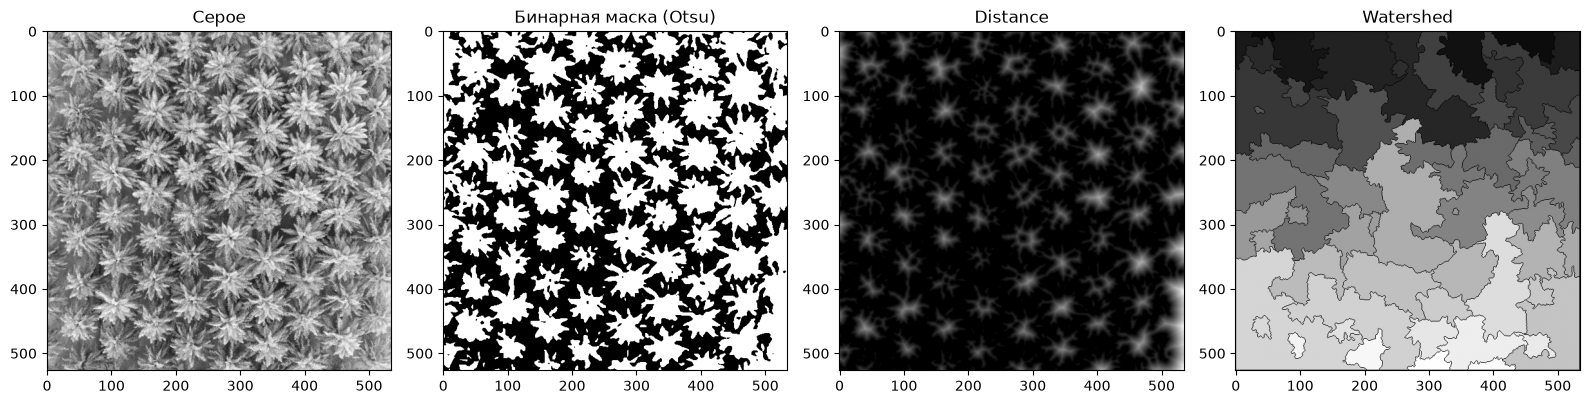

In [11]:
n_palms = ret - 1           

print('Найдено пальм:', n_palms)

plt.figure(figsize=(16, 5))
plt.subplot(1, 4, 1); plt.imshow(image_gray, cmap='gray'); plt.title('Серое')
plt.subplot(1, 4, 2); plt.imshow(thresh, cmap='gray'); plt.title('Бинарная маска (Otsu)')
plt.subplot(1, 4, 3); plt.imshow(dist,       cmap='gray'); plt.title('Distance')
plt.subplot(1, 4, 4); plt.imshow(markers, cmap='gray'); plt.title('Watershed')

plt.tight_layout()
plt.show()